# CPI model training experiment (Colab runtime)

This notebook clones the MIT-licensed `ketandeshmukh1920/p2-india-cpi-forecasting` repository, loads its monthly CPI/macro panel, evaluates one-month-ahead models with expanding walk-forward validation, then saves newly trained artifacts and evaluation results.

**Important:** the repository provides training code/data and reported results, not a plug-and-play trained-model bundle. This notebook retrains comparable ARIMA, ARIMAX, Elastic Net, and XGBoost models. They are experimental benchmarks, not policy advice or production-ready forecasts.

Run cells from top to bottom. The training inputs are cloned into this remote runtime. Outputs go to Google Drive when available; otherwise they stay in `/content/model_training_outputs` and must be downloaded before the runtime ends.

## 1. Connect storage and choose output folders

If this kernel is connected to Colab, approve the Google Drive mount prompt. If it is another remote Jupyter runtime, the notebook uses its `/content` folder instead.

In [1]:
from pathlib import Path
import subprocess
import sys

try:
    from google.colab import drive
except ImportError:
    OUTPUT_ROOT = Path('/content/model_training_outputs')
else:
    drive.mount('/content/drive')
    OUTPUT_ROOT = Path('/content/drive/MyDrive/agentic-monetary-policy-india/training_runs')

WORK_ROOT = Path('/content/external_research')
REPO_DIR = WORK_ROOT / 'p2-india-cpi-forecasting'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
WORK_ROOT.mkdir(parents=True, exist_ok=True)
print('Python:', sys.version)
print('Training repo:', REPO_DIR)
print('Training outputs:', OUTPUT_ROOT)

Mounted at /content/drive
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Training repo: /content/external_research/p2-india-cpi-forecasting
Training outputs: /content/drive/MyDrive/agentic-monetary-policy-india/training_runs


## 2. Download the repository, dataset, and license

The repository's `data/master_data1.csv` is the training panel. The code checks that an existing clone is the expected repository instead of overwriting it.

In [2]:
REPO_URL = 'https://github.com/ketandeshmukh1920/p2-india-cpi-forecasting.git'
if REPO_DIR.exists():
    if not (REPO_DIR / '.git').is_dir():
        raise FileExistsError(f'Expected a Git clone at {REPO_DIR}, but that path already exists and is not a Git repository.')
    origin = subprocess.check_output(
        ['git', '-C', str(REPO_DIR), 'remote', 'get-url', 'origin'], text=True
    ).strip()
    if origin.removesuffix('.git').lower() != REPO_URL.removesuffix('.git').lower():
        raise ValueError(f'Unexpected Git remote at {REPO_DIR}: {origin}')
else:
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)

DATA_FILE = REPO_DIR / 'data' / 'master_data1.csv'
LICENSE_FILE = REPO_DIR / 'LICENSE'
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'Repository dataset is missing: {DATA_FILE}')
if not LICENSE_FILE.is_file():
    raise FileNotFoundError(f'Expected MIT license file is missing: {LICENSE_FILE}')
REPO_COMMIT = subprocess.check_output(
    ['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True
).strip()
print('Checked-out commit:', REPO_COMMIT)
print('Dataset:', DATA_FILE, f'({DATA_FILE.stat().st_size:,} bytes)')
print('License: MIT; retain its notice with redistributed code/artifacts.')
print(LICENSE_FILE.read_text(encoding='utf-8')[:500])

Checked-out commit: ce8abb01d2ec0fd7524638995281e32a8142f1d1
Dataset: /content/external_research/p2-india-cpi-forecasting/data/master_data1.csv (14,419 bytes)
License: MIT; retain its notice with redistributed code/artifacts.
MIT License

Copyright (c) 2026 ketandeshmukh1920

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyr


## 3. Install training dependencies

This installs the packages needed for the models and evaluation below. Restart the kernel only if the notebook environment asks you to.

In [3]:
%pip install -q numpy pandas scikit-learn statsmodels xgboost joblib matplotlib

## 4. Load and validate the monthly data

The target is `cpi_inflation` (percent). This check verifies required columns, date uniqueness, monthly continuity, and numeric values before any model is fit.

In [4]:
import hashlib
import json
import shutil

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
import xgboost
from sklearn.base import clone
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.arima.model import ARIMA
from xgboost import XGBRegressor

TARGET = 'cpi_inflation'
MACRO_COLUMNS = [
    'iip', 'm3', 'repo_rate', 'tbill_91d', 'gsec_10yr',
    'inr_usd', 'fed_funds_rate', 'crude_oil_brent', 'term_spread'
]
required = ['date', TARGET, *MACRO_COLUMNS]
raw = pd.read_csv(DATA_FILE)
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Dataset is missing required columns: {missing_columns}')

raw['date'] = pd.to_datetime(raw['date'], errors='raise')
raw = raw.sort_values('date').set_index('date')
if raw.index.has_duplicates:
    raise ValueError('Dataset contains duplicate monthly dates.')
expected_dates = pd.date_range(raw.index.min(), raw.index.max(), freq='MS')
if not raw.index.equals(expected_dates):
    raise ValueError('Dataset is not a complete, month-start monthly series; inspect date gaps before training.')

for column in [TARGET, *MACRO_COLUMNS]:
    raw[column] = pd.to_numeric(raw[column], errors='coerce')
missing_counts = raw[[TARGET, *MACRO_COLUMNS]].isna().sum()
print('Rows:', len(raw), '| Coverage:', raw.index.min().date(), 'to', raw.index.max().date())
print('Missing values by column:')
display(missing_counts.to_frame('missing'))
if missing_counts.sum():
    raise ValueError('Missing/non-numeric values found. Resolve them explicitly rather than silently dropping rows.')
display(raw.head())

Rows: 172 | Coverage: 2012-01-01 to 2026-04-01
Missing values by column:


,missing
cpi_inflation,0
iip,0
m3,0
repo_rate,0
tbill_91d,0
gsec_10yr,0
inr_usd,0
fed_funds_rate,0
crude_oil_brent,0
term_spread,0


,iip,m3,repo_rate,tbill_91d,gsec_10yr,inr_usd,cpi_inflation,fed_funds_rate,crude_oil_brent,term_spread
date,,,,,,,,,,
2012-01-01,0.966458,14.847322,8.5,8.7293,8.270,49.6825,7.65,0.08,111.415000,-0.4593
2012-02-01,4.285714,13.921438,8.5,9.0646,8.445,48.9408,8.83,0.10,119.165714,-0.6196
2012-03-01,-2.848265,13.233486,8.5,9.0227,8.620,51.1565,9.38,0.13,124.703182,-0.4027
2012-04-01,-1.263538,13.269282,8.0,8.3946,8.650,52.5193,10.26,0.14,120.470000,0.2554
2012-05-01,2.466907,13.845944,8.0,8.3946,8.380,56.4225,10.36,0.16,110.822174,-0.0146


## 5. Build leakage-conscious features and define the test period

All macro inputs are shifted by one month; CPI lags use only prior months. We evaluate one-month-ahead forecasts from January 2022 onward using expanding training windows. This is a benchmark design, not proof that every source release was available on each historical forecast date.

In [5]:
features = pd.DataFrame(index=raw.index)
for column in MACRO_COLUMNS:
    features[f'{column}_lag1'] = raw[column].shift(1)
for lag in (1, 2, 3):
    features[f'cpi_lag{lag}'] = raw[TARGET].shift(lag)
features['m3_lag12'] = raw['m3'].shift(12)

panel = features.copy()
panel[TARGET] = raw[TARGET]
panel = panel.dropna()
FEATURE_COLUMNS = features.columns.tolist()
TEST_START = pd.Timestamp('2022-01-01')
test_dates = panel.index[panel.index >= TEST_START]
if len(test_dates) == 0:
    raise ValueError(f'No observations at or after test start {TEST_START.date()}.')
if panel.index[panel.index < TEST_START].empty:
    raise ValueError('No pre-test observations remain for model training.')
print('Model rows after lag construction:', len(panel))
print('Feature count:', len(FEATURE_COLUMNS))
print('Expanding-window test:', test_dates.min().date(), 'to', test_dates.max().date(), f'({len(test_dates)} months)')
display(panel.head())

Model rows after lag construction: 160
Feature count: 13
Expanding-window test: 2022-01-01 to 2026-04-01 (52 months)


,iip_lag1,m3_lag1,repo_rate_lag1,tbill_91d_lag1,gsec_10yr_lag1,inr_usd_lag1,fed_funds_rate_lag1,crude_oil_brent_lag1,term_spread_lag1,cpi_lag1,cpi_lag2,cpi_lag3,m3_lag12,cpi_inflation
date,,,,,,,,,,,,,,
2013-01-01,-0.554631,11.248883,8.00,8.1857,8.05,54.7773,0.16,109.569048,-0.1357,10.56,9.90,9.75,14.847322,10.79
2013-02-01,2.477477,7.895346,7.75,7.9353,7.91,53.2890,0.14,112.527826,-0.0253,10.79,10.56,9.90,13.921438,10.91
2013-03-01,0.570776,8.908053,7.75,8.1022,7.87,53.7735,0.15,116.488000,-0.2322,10.91,10.79,10.56,13.233486,10.39
2013-04-01,3.518124,9.216803,7.50,8.1857,7.95,54.3893,0.14,109.585714,-0.2357,10.39,10.91,10.79,13.269282,9.39
2013-05-01,1.462523,8.759476,7.50,7.5602,7.73,54.2190,0.15,102.960000,0.1698,9.39,10.39,10.91,13.845944,9.31


## 6. Walk-forward evaluation

Each test month is predicted using only earlier rows, then the window expands. Metrics are MAE and RMSE in CPI inflation percentage points. No random train/test split is used.

In [6]:
sklearn_models = {
    'ElasticNet': make_pipeline(
        StandardScaler(),
        ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000, random_state=42)
    ),
    'XGBoost': XGBRegressor(
        objective='reg:squarederror', n_estimators=100, max_depth=2,
        learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=10.0, random_state=42, n_jobs=2, verbosity=0
    ),
}
predictions = {name: [] for name in ['Persistence', 'ARIMA(3,0,0)', 'ARIMAX(3,0,0)', *sklearn_models]}
actuals = []
prediction_dates = []

for date in test_dates:
    train = panel.loc[panel.index < date]
    test_x = panel.loc[[date], FEATURE_COLUMNS]
    if len(train) < 24:
        raise ValueError(f'Insufficient history before {date.date()}: {len(train)} rows.')
    y_train = train[TARGET]
    actuals.append(float(panel.at[date, TARGET]))
    prediction_dates.append(date)

    predictions['Persistence'].append(float(test_x['cpi_lag1'].iloc[0]))
    arima_fit = ARIMA(y_train, order=(3, 0, 0)).fit()
    predictions['ARIMA(3,0,0)'].append(float(arima_fit.forecast(steps=1).iloc[0]))
    arimax_fit = ARIMA(
        y_train, order=(3, 0, 0), exog=train[FEATURE_COLUMNS]
    ).fit()
    predictions['ARIMAX(3,0,0)'].append(
        float(arimax_fit.forecast(steps=1, exog=test_x).iloc[0])
    )

    for name, estimator in sklearn_models.items():
        fitted = clone(estimator)
        fitted.fit(train[FEATURE_COLUMNS], y_train)
        predictions[name].append(float(fitted.predict(test_x)[0]))

actual_series = pd.Series(actuals, index=pd.DatetimeIndex(prediction_dates), name='actual')
prediction_frame = pd.DataFrame(predictions, index=actual_series.index)
metric_rows = []
for name in prediction_frame.columns:
    pred = prediction_frame[name]
    metric_rows.append({
        'model': name,
        'test_start': str(actual_series.index.min().date()),
        'test_end': str(actual_series.index.max().date()),
        'n_test': len(actual_series),
        'mae_percentage_points': mean_absolute_error(actual_series, pred),
        'rmse_percentage_points': np.sqrt(mean_squared_error(actual_series, pred)),
    })
metrics = pd.DataFrame(metric_rows).sort_values('rmse_percentage_points').reset_index(drop=True)
display(metrics.round(4))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

,model,test_start,test_end,n_test,mae_percentage_points,rmse_percentage_points
0,"ARIMA(3,0,0)",2022-01-01,2026-04-01,52,0.5397,0.7024
1,"ARIMAX(3,0,0)",2022-01-01,2026-04-01,52,0.5433,0.7283
2,Persistence,2022-01-01,2026-04-01,52,0.5872,0.7844
3,ElasticNet,2022-01-01,2026-04-01,52,0.6242,0.8111
4,XGBoost,2022-01-01,2026-04-01,52,0.7588,1.0190


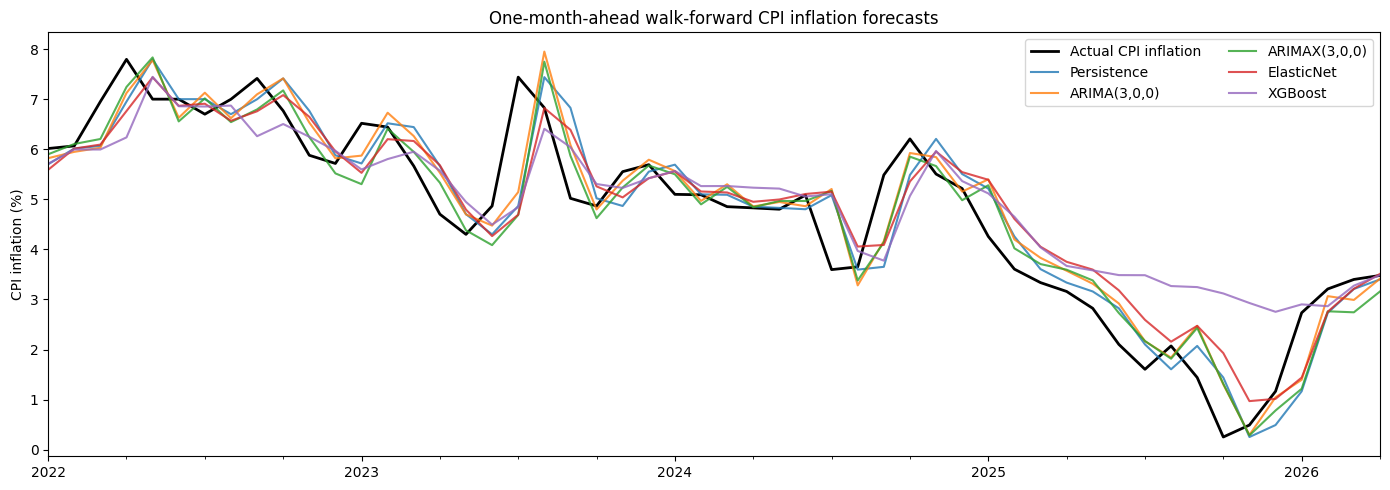

In [7]:
ax = actual_series.plot(figsize=(14, 5), color='black', linewidth=2, label='Actual CPI inflation')
for model_name in prediction_frame.columns:
    prediction_frame[model_name].plot(ax=ax, alpha=0.8, label=model_name)
ax.set_title('One-month-ahead walk-forward CPI inflation forecasts')
ax.set_ylabel('CPI inflation (%)')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 7. Fit final models on all available observations and save artifacts

The saved models are refit on the complete available panel after evaluation. Keep their input feature order and one-month lag definitions with the artifacts. These files are not automatically wired into the project's API.

In [8]:
from datetime import datetime, timezone

run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
ARTIFACT_DIR = OUTPUT_ROOT / f'p2_cpi_training_{run_stamp}'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=False)

final_models = {}
final_models['arima_300'] = ARIMA(panel[TARGET], order=(3, 0, 0)).fit()
final_models['arimax_300'] = ARIMA(
    panel[TARGET], order=(3, 0, 0), exog=panel[FEATURE_COLUMNS]
).fit()
for name, estimator in sklearn_models.items():
    fitted = clone(estimator)
    fitted.fit(panel[FEATURE_COLUMNS], panel[TARGET])
    final_models[name.lower()] = fitted

for name, model in final_models.items():
    joblib.dump(model, ARTIFACT_DIR / f'{name}.joblib')

metrics.to_csv(ARTIFACT_DIR / 'walk_forward_metrics.csv', index=False)
prediction_frame.assign(actual=actual_series).to_csv(ARTIFACT_DIR / 'walk_forward_predictions.csv', index_label='date')
shutil.copy2(LICENSE_FILE, ARTIFACT_DIR / 'LICENSE-p2-india-cpi-forecasting.txt')

dataset_hash = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
metadata = {
    'source_repository': 'https://github.com/ketandeshmukh1920/p2-india-cpi-forecasting',
    'source_commit': REPO_COMMIT,
    'dataset_path': 'data/master_data1.csv',
    'dataset_sha256': dataset_hash,
    'source_license': 'MIT (see LICENSE-p2-india-cpi-forecasting.txt)',
    'target': TARGET,
    'target_unit': 'percent CPI inflation; errors are percentage points',
    'feature_columns_in_order': FEATURE_COLUMNS,
    'macro_features_lag_months': 1,
    'cpi_lags_months': [1, 2, 3],
    'm3_additional_lag_months': 12,
    'validation': {
        'method': 'expanding one-step walk-forward; fit uses observations strictly before forecast month',
        'test_start': str(actual_series.index.min().date()),
        'test_end': str(actual_series.index.max().date()),
        'test_observations': int(len(actual_series)),
    },
    'training_period': {
        'start': str(panel.index.min().date()),
        'end': str(panel.index.max().date()),
        'observations': int(len(panel)),
    },
    'models': list(final_models),
    'versions': {
        'python': sys.version.split()[0],
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'statsmodels': statsmodels.__version__,
        'xgboost': xgboost.__version__,
    },
    'limitations': [
        'Experimental benchmark; not production-ready or policy advice.',
        'Historical release vintages and point-in-time availability were not verified.',
        'Small single-country monthly sample; evaluate on future data before deployment.',
        'Do not load joblib/pickle artifacts from untrusted sources.',
    ],
}
(ARTIFACT_DIR / 'training_metadata.json').write_text(
    json.dumps(metadata, indent=2), encoding='utf-8'
)
(ARTIFACT_DIR / 'README.txt').write_text(
    'Experimental CPI training run. See training_metadata.json for provenance, features, validation, and limitations.\n',
    encoding='utf-8'
)

print('Saved artifacts to:', ARTIFACT_DIR)
for path in sorted(ARTIFACT_DIR.iterdir()):
    print(path.name, f'({path.stat().st_size:,} bytes)')

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

Saved artifacts to: /content/drive/MyDrive/agentic-monetary-policy-india/training_runs/p2_cpi_training_20261015T071150Z
LICENSE-p2-india-cpi-forecasting.txt (1,074 bytes)
README.txt (113 bytes)
arima_300.joblib (536,603 bytes)
arimax_300.joblib (705,716 bytes)
elasticnet.joblib (1,976 bytes)
training_metadata.json (1,748 bytes)
walk_forward_metrics.csv (454 bytes)
walk_forward_predictions.csv (5,377 bytes)
xgboost.joblib (100,997 bytes)


## 8. What to do with the results

Review `walk_forward_metrics.csv` and prediction plots first. Do not choose a model solely because it has the lowest score on this one test period. The cloned repo's README reports that its XGBoost-only model underperformed ARIMA and that its hybrid gains were small; this notebook deliberately treats the models as comparators rather than presumed improvements.

The timestamped run folder in Google Drive contains the trained joblib files, walk-forward forecasts/metrics, a training metadata manifest, and the MIT notice. The current app does not load these artifacts automatically. Integration requires a separate adapter, matching inputs/feature timing, and a fresh compatibility and backtest review.

## 9. Verify saved artifacts and create a portable ZIP

This reloads every saved model from the run folder, checks the saved metrics and predictions, runs a prediction smoke test for each model, reports statsmodels convergence flags, and creates a ZIP beside the run folder. A `converged=False` result is a warning to investigate before using that model.

In [9]:
required_artifacts = [
    'arima_300.joblib',
    'arimax_300.joblib',
    'elasticnet.joblib',
    'xgboost.joblib',
    'walk_forward_metrics.csv',
    'walk_forward_predictions.csv',
    'training_metadata.json',
    'LICENSE-p2-india-cpi-forecasting.txt',
]
missing_artifacts = [name for name in required_artifacts if not (ARTIFACT_DIR / name).is_file()]
if missing_artifacts:
    raise FileNotFoundError(f'Missing saved artifacts: {missing_artifacts}')

saved_metrics = pd.read_csv(ARTIFACT_DIR / 'walk_forward_metrics.csv')
saved_predictions = pd.read_csv(ARTIFACT_DIR / 'walk_forward_predictions.csv', parse_dates=['date'])
saved_metadata = json.loads((ARTIFACT_DIR / 'training_metadata.json').read_text(encoding='utf-8'))
if len(saved_metrics) != len(metrics) or len(saved_predictions) != len(actual_series):
    raise AssertionError('Saved metric or prediction row count differs from the in-memory evaluation.')
if saved_predictions.isna().any().any():
    raise AssertionError('Saved walk-forward predictions contain missing values.')
if saved_metadata['source_commit'] != REPO_COMMIT:
    raise AssertionError('Saved metadata commit does not match the cloned source commit.')
if saved_metadata['dataset_sha256'] != hashlib.sha256(DATA_FILE.read_bytes()).hexdigest():
    raise AssertionError('Saved metadata dataset hash does not match the downloaded dataset.')

loaded_models = {
    name: joblib.load(ARTIFACT_DIR / f'{name}.joblib')
    for name in ('arima_300', 'arimax_300', 'elasticnet', 'xgboost')
}
latest_features = panel[FEATURE_COLUMNS].tail(1)
smoke_rows = []
for name, model in loaded_models.items():
    if name == 'arima_300':
        smoke_prediction = float(model.forecast(steps=1).iloc[0])
    elif name == 'arimax_300':
        smoke_prediction = float(model.forecast(steps=1, exog=latest_features).iloc[0])
    else:
        smoke_prediction = float(model.predict(latest_features)[0])
    if not np.isfinite(smoke_prediction):
        raise AssertionError(f'{name} produced a non-finite smoke-test prediction.')
    retvals = getattr(model, 'mle_retvals', {})
    converged = retvals.get('converged') if isinstance(retvals, dict) else None
    smoke_rows.append({'model': name, 'smoke_prediction': smoke_prediction, 'optimizer_converged': converged})

display(saved_metrics.round(4))
display(pd.DataFrame(smoke_rows))
print('Verified source commit:', saved_metadata['source_commit'])
print('Verified dataset SHA-256:', saved_metadata['dataset_sha256'])

BUNDLE_PATH = Path(shutil.make_archive(
    str(ARTIFACT_DIR), 'zip', root_dir=str(ARTIFACT_DIR)
))
if not BUNDLE_PATH.is_file() or BUNDLE_PATH.stat().st_size == 0:
    raise OSError(f'Artifact ZIP was not created correctly: {BUNDLE_PATH}')
print('Portable bundle:', BUNDLE_PATH)
print(f'ZIP size: {BUNDLE_PATH.stat().st_size:,} bytes')
print('The ZIP is saved beside the run folder in Google Drive (if mounted).')

,model,test_start,test_end,n_test,mae_percentage_points,rmse_percentage_points
0,"ARIMA(3,0,0)",2022-01-01,2026-04-01,52,0.5397,0.7024
1,"ARIMAX(3,0,0)",2022-01-01,2026-04-01,52,0.5433,0.7283
2,Persistence,2022-01-01,2026-04-01,52,0.5872,0.7844
3,ElasticNet,2022-01-01,2026-04-01,52,0.6242,0.8111
4,XGBoost,2022-01-01,2026-04-01,52,0.7588,1.0190


,model,smoke_prediction,optimizer_converged
0,arima_300,3.540815,True
1,arimax_300,3.236806,False
2,elasticnet,3.511383,None
3,xgboost,3.576357,None


Verified source commit: ce8abb01d2ec0fd7524638995281e32a8142f1d1
Verified dataset SHA-256: 5ce2206c99358cc5816de7372fb6d1fe1952348834f5c4f273d03ed55135ae7f
Portable bundle: /content/drive/MyDrive/agentic-monetary-policy-india/training_runs/p2_cpi_training_20261015T071150Z.zip
ZIP size: 237,079 bytes
The ZIP is saved beside the run folder in Google Drive (if mounted).


In [10]:
from pathlib import Path
import hashlib
import json
import shutil

import joblib
import numpy as np
import pandas as pd

# Confirm the training cell created the expected files.
required_files = [
    "arima_300.joblib",
    "arimax_300.joblib",
    "elasticnet.joblib",
    "xgboost.joblib",
    "walk_forward_metrics.csv",
    "walk_forward_predictions.csv",
    "training_metadata.json",
    "LICENSE-p2-india-cpi-forecasting.txt",
]

missing_files = [
    filename
    for filename in required_files
    if not (ARTIFACT_DIR / filename).is_file()
]
if missing_files:
    raise FileNotFoundError(
        f"Missing files in {ARTIFACT_DIR}: {missing_files}"
    )

# Load and check the saved reports and metadata.
saved_metrics = pd.read_csv(ARTIFACT_DIR / "walk_forward_metrics.csv")
saved_predictions = pd.read_csv(
    ARTIFACT_DIR / "walk_forward_predictions.csv",
    parse_dates=["date"],
)
saved_metadata = json.loads(
    (ARTIFACT_DIR / "training_metadata.json").read_text(encoding="utf-8")
)

if len(saved_metrics) != len(metrics):
    raise AssertionError("Saved metrics do not match the current evaluation.")

if len(saved_predictions) != len(actual_series):
    raise AssertionError("Saved predictions do not match the current evaluation.")

if saved_predictions.isna().any().any():
    raise AssertionError("The saved predictions contain missing values.")

if saved_metadata["source_commit"] != REPO_COMMIT:
    raise AssertionError("Source commit does not match the training metadata.")

current_dataset_hash = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
if saved_metadata["dataset_sha256"] != current_dataset_hash:
    raise AssertionError("Dataset checksum does not match the training metadata.")

# Reload every model and check that it can produce a finite prediction.
model_names = ["arima_300", "arimax_300", "elasticnet", "xgboost"]
loaded_models = {
    name: joblib.load(ARTIFACT_DIR / f"{name}.joblib")
    for name in model_names
}

latest_features = panel[FEATURE_COLUMNS].tail(1)
smoke_test_results = []

for name, model in loaded_models.items():
    if name == "arima_300":
        prediction = float(model.forecast(steps=1).iloc[0])
    elif name == "arimax_300":
        prediction = float(
            model.forecast(steps=1, exog=latest_features).iloc[0]
        )
    else:
        prediction = float(model.predict(latest_features)[0])

    if not np.isfinite(prediction):
        raise ValueError(f"{name} returned a non-finite prediction.")

    optimizer_results = getattr(model, "mle_retvals", {})
    converged = (
        optimizer_results.get("converged")
        if isinstance(optimizer_results, dict)
        else None
    )

    smoke_test_results.append({
        "model": name,
        "smoke_test_prediction": prediction,
        "optimizer_converged": converged,
    })

print("Saved evaluation metrics:")
display(saved_metrics.round(4))

print("Model reload and prediction checks:")
display(pd.DataFrame(smoke_test_results))

print("Verified source commit:", saved_metadata["source_commit"])
print("Verified dataset SHA-256:", current_dataset_hash)

# Create a ZIP archive beside the run folder.
bundle_base = ARTIFACT_DIR.parent / f"{ARTIFACT_DIR.name}_bundle"
bundle_path = Path(
    shutil.make_archive(
        str(bundle_base),
        "zip",
        root_dir=str(ARTIFACT_DIR),
    )
)

if not bundle_path.is_file() or bundle_path.stat().st_size == 0:
    raise OSError(f"ZIP archive was not created correctly: {bundle_path}")

print("Portable bundle:", bundle_path)
print(f"ZIP size: {bundle_path.stat().st_size:,} bytes")

Saved evaluation metrics:


,model,test_start,test_end,n_test,mae_percentage_points,rmse_percentage_points
0,"ARIMA(3,0,0)",2022-01-01,2026-04-01,52,0.5397,0.7024
1,"ARIMAX(3,0,0)",2022-01-01,2026-04-01,52,0.5433,0.7283
2,Persistence,2022-01-01,2026-04-01,52,0.5872,0.7844
3,ElasticNet,2022-01-01,2026-04-01,52,0.6242,0.8111
4,XGBoost,2022-01-01,2026-04-01,52,0.7588,1.0190


Model reload and prediction checks:


,model,smoke_test_prediction,optimizer_converged
0,arima_300,3.540815,True
1,arimax_300,3.236806,False
2,elasticnet,3.511383,None
3,xgboost,3.576357,None


Verified source commit: ce8abb01d2ec0fd7524638995281e32a8142f1d1
Verified dataset SHA-256: 5ce2206c99358cc5816de7372fb6d1fe1952348834f5c4f273d03ed55135ae7f
Portable bundle: /content/drive/MyDrive/agentic-monetary-policy-india/training_runs/p2_cpi_training_20261015T071150Z_bundle.zip
ZIP size: 237,079 bytes
